In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C3"
DTYPE="HSV"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C3_10,27,"[DATA/TRAINING/C3/C3_10/IMG_6627.HEIC, DATA/TR..."
1,C3_11,27,"[DATA/TRAINING/C3/C3_11/IMG_6732.HEIC, DATA/TR..."
2,C3_12,27,"[DATA/TRAINING/C3/C3_12/IMG_6854.HEIC, DATA/TR..."
3,C3_13,30,"[DATA/TRAINING/C3/C3_13/IMG_7002.HEIC, DATA/TR..."
4,C3_14,27,"[DATA/TRAINING/C3/C3_14/IMG_7249.HEIC, DATA/TR..."
5,C3_15,26,"[DATA/TRAINING/C3/C3_15/IMG_7385.HEIC, DATA/TR..."
6,C3_16,26,"[DATA/TRAINING/C3/C3_16/IMG_7516.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [6]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

In [7]:
def hsv_histogram(image, bins):
    #print(mask)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    #The 3D color histogram is extracted from the mask area of the image using the bin number of each channel provided
    hist = cv2.calcHist([image], [0, 1, 2], None, [bins, bins, bins], [0, 180, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    #Return histogram
    return hist

Text(0.5, 1.0, '16% IMG_7568.HEIC')

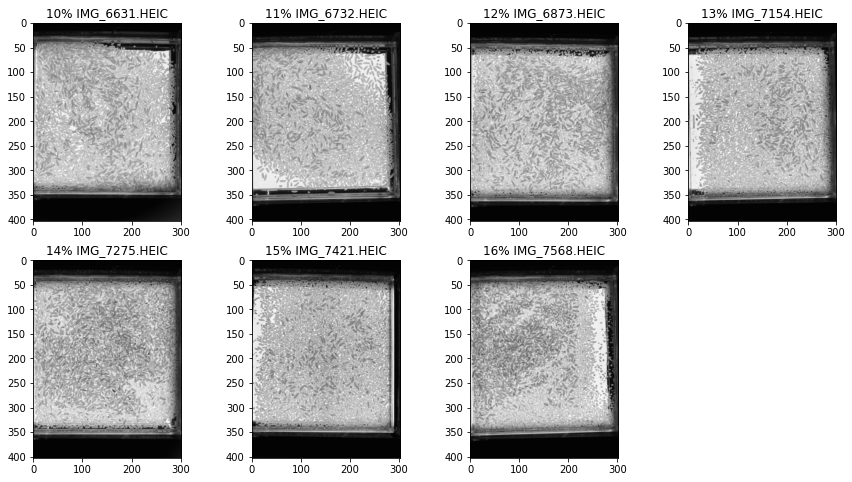

In [39]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [160]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
scale=25
bins=16
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        
        arr_img_hist.append(hsv_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [161]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.487339,0.160204,0.092219,0.075384,0.056188,0.053482,0.051003,0.087521,0.191834,0.254617,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6627.HEIC,10
1,0.519957,0.142151,0.118555,0.062899,0.048761,0.041473,0.045360,0.053438,0.129149,0.228511,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6628.HEIC,10
2,0.510018,0.162991,0.084520,0.059774,0.055160,0.056814,0.058439,0.066979,0.128034,0.289782,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6629.HEIC,10
3,0.529269,0.155866,0.112518,0.065156,0.056880,0.050511,0.057874,0.081783,0.168339,0.303294,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6630.HEIC,10
4,0.499173,0.157453,0.086690,0.061514,0.055095,0.056210,0.056899,0.072601,0.140657,0.275665,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6631.HEIC,10
5,0.504544,0.132101,0.103508,0.069444,0.056145,0.049832,0.053984,0.079112,0.163575,0.316778,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6632.HEIC,10
6,0.556548,0.153299,0.078661,0.043896,0.043542,0.048015,0.047257,0.095367,0.192351,0.352872,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6633.HEIC,10
7,0.486532,0.152702,0.100734,0.070894,0.058908,0.051348,0.053641,0.089385,0.197541,0.346582,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6634.HEIC,10
8,0.521977,0.134441,0.127890,0.080371,0.058785,0.048826,0.050088,0.079395,0.179638,0.339208,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6635.HEIC,10
9,0.525144,0.110540,0.110980,0.081451,0.055795,0.053633,0.052805,0.085600,0.174161,0.322918,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6636.HEIC,10


# Classification

In [162]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [163]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [164]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [165]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [166]:
TYPE="CV"

In [167]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.857143,0.857143,0.857143,HSV,C3,RF_C,25,16,1008,756,3
1,2,0.736842,0.752381,0.714286,0.732839,HSV,C3,RF_C,25,16,1008,756,3
2,3,0.631579,0.666667,0.619048,0.641975,HSV,C3,RF_C,25,16,1008,756,3
3,4,0.684211,0.785714,0.690476,0.735023,HSV,C3,RF_C,25,16,1008,756,3
4,5,0.684211,0.833333,0.690476,0.755208,HSV,C3,RF_C,25,16,1008,756,3
5,6,0.578947,0.528571,0.547619,0.537927,HSV,C3,RF_C,25,16,1008,756,3
6,7,0.684211,0.726190,0.714286,0.720189,HSV,C3,RF_C,25,16,1008,756,3
7,8,0.526316,0.514286,0.547619,0.530429,HSV,C3,RF_C,25,16,1008,756,3
8,9,0.684211,0.759524,0.690476,0.723356,HSV,C3,RF_C,25,16,1008,756,3
9,10,0.947368,0.964286,0.952381,0.958296,HSV,C3,RF_C,25,16,1008,756,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C3,RF_C,0.7,0.702381,0.719239,0.73881


### MLP Classifier

In [170]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [171]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [172]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.578947,0.690476,0.595238,0.639330,HSV,C3,MLP_C,25,16,1008,756,3
1,2,0.736842,0.726190,0.714286,0.720189,HSV,C3,MLP_C,25,16,1008,756,3
2,3,0.789474,0.833333,0.809524,0.821256,HSV,C3,MLP_C,25,16,1008,756,3
3,4,0.736842,0.833333,0.738095,0.782828,HSV,C3,MLP_C,25,16,1008,756,3
4,5,0.684211,0.573810,0.666667,0.616763,HSV,C3,MLP_C,25,16,1008,756,3
5,6,0.684211,0.809524,0.714286,0.758929,HSV,C3,MLP_C,25,16,1008,756,3
6,7,0.631579,0.630952,0.619048,0.624943,HSV,C3,MLP_C,25,16,1008,756,3
7,8,0.684211,0.642857,0.642857,0.642857,HSV,C3,MLP_C,25,16,1008,756,3
8,9,0.526316,0.595238,0.547619,0.570437,HSV,C3,MLP_C,25,16,1008,756,3
9,10,0.473684,0.652381,0.523810,0.581068,HSV,C3,MLP_C,25,16,1008,756,3


In [173]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C3,MLP_C,0.652632,0.657143,0.67586,0.69881


### XGBoost Classifier

In [174]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [175]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.684211,0.766667,0.666667,0.713178,HSV,C3,XGB_C,25,16,1008,756,3
1,2,0.578947,0.576190,0.547619,0.561542,HSV,C3,XGB_C,25,16,1008,756,3
2,3,0.578947,0.619048,0.571429,0.594286,HSV,C3,XGB_C,25,16,1008,756,3
3,4,0.789474,0.821429,0.785714,0.803175,HSV,C3,XGB_C,25,16,1008,756,3
4,5,0.578947,0.714286,0.547619,0.619946,HSV,C3,XGB_C,25,16,1008,756,3
5,6,0.631579,0.642857,0.642857,0.642857,HSV,C3,XGB_C,25,16,1008,756,3
6,7,0.631579,0.678571,0.619048,0.647444,HSV,C3,XGB_C,25,16,1008,756,3
7,8,0.473684,0.576190,0.476190,0.521439,HSV,C3,XGB_C,25,16,1008,756,3
8,9,0.684211,0.823129,0.666667,0.736682,HSV,C3,XGB_C,25,16,1008,756,3
9,10,0.684211,0.785714,0.666667,0.721311,HSV,C3,XGB_C,25,16,1008,756,3


In [176]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HSV,C3,XGB_C,0.631579,0.619048,0.656186,0.700408


# External validation

In [177]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C3_10,5,"[DATA/TEST/C3/C3_10/IMG_6622.HEIC, DATA/TEST/C..."
1,C3_11,5,"[DATA/TEST/C3/C3_11/IMG_6717.HEIC, DATA/TEST/C..."
2,C3_12,5,"[DATA/TEST/C3/C3_12/IMG_6845.HEIC, DATA/TEST/C..."
3,C3_13,5,"[DATA/TEST/C3/C3_13/IMG_6987.HEIC, DATA/TEST/C..."
4,C3_14,5,"[DATA/TEST/C3/C3_14/IMG_7239.HEIC, DATA/TEST/C..."
5,C3_15,5,"[DATA/TEST/C3/C3_15/IMG_7376.HEIC, DATA/TEST/C..."
6,C3_16,5,"[DATA/TEST/C3/C3_16/IMG_7506.HEIC, DATA/TEST/C..."


In [178]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [179]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        arr_img_hist.append(hsv_histogram(image, bins))
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [180]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,4093,4094,4095,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.569985,0.140109,0.086720,0.044885,0.031744,0.032000,0.044601,0.074531,0.149717,0.222529,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6622.HEIC,10
1,0.580212,0.132003,0.085870,0.039043,0.036726,0.031711,0.038451,0.060385,0.164781,0.225244,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6623.HEIC,10
2,0.558560,0.151939,0.101601,0.043911,0.042571,0.040822,0.051118,0.061579,0.145937,0.273249,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6624.HEIC,10
3,0.543458,0.143600,0.097409,0.048489,0.042028,0.042361,0.052952,0.062886,0.145143,0.248871,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6625.HEIC,10
4,0.472585,0.146344,0.088383,0.066002,0.052498,0.047500,0.049974,0.057757,0.110694,0.173099,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6626.HEIC,10
0,0.537155,0.162313,0.071454,0.060090,0.056306,0.051616,0.049633,0.070049,0.206238,0.261311,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6717.HEIC,11
1,0.561534,0.151944,0.107372,0.069966,0.052737,0.042575,0.043543,0.071485,0.182834,0.289578,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6721.HEIC,11
2,0.519621,0.124818,0.096988,0.073134,0.053004,0.040382,0.038972,0.057580,0.136463,0.207521,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6724.HEIC,11
3,0.552519,0.155993,0.092975,0.061444,0.051213,0.042323,0.044835,0.067277,0.118525,0.216296,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6728.HEIC,11
4,0.532048,0.148063,0.083613,0.067268,0.057424,0.045293,0.042834,0.060619,0.140996,0.223955,...,0.0,0.0,0.0,25,16,1008,756,3,IMG_6731.HEIC,11


In [181]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [182]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [183]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [184]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [185]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.57      0.80      0.67         5
     Class 2       1.00      0.80      0.89         5
     Class 3       0.25      0.40      0.31         5
     Class 4       0.60      0.60      0.60         5
     Class 5       0.33      0.20      0.25         5
     Class 6       0.60      0.60      0.60         5

    accuracy                           0.49        35
   macro avg       0.48      0.49      0.47        35
weighted avg       0.48      0.49      0.47        35



## MLP

In [186]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [187]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.40      0.44         5
     Class 1       0.43      0.60      0.50         5
     Class 2       0.60      0.60      0.60         5
     Class 3       0.17      0.20      0.18         5
     Class 4       0.50      0.60      0.55         5
     Class 5       1.00      0.20      0.33         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.49        35
   macro avg       0.55      0.49      0.48        35
weighted avg       0.55      0.49      0.48        35



## XGBC

In [188]:
y_pred = modelXGBC.predict(X_test_scale) 

In [189]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.29      0.40      0.33         5
     Class 2       0.67      0.40      0.50         5
     Class 3       0.33      0.40      0.36         5
     Class 4       0.43      0.60      0.50         5
     Class 5       0.50      0.60      0.55         5
     Class 6       1.00      0.40      0.57         5

    accuracy                           0.40        35
   macro avg       0.46      0.40      0.40        35
weighted avg       0.46      0.40      0.40        35

